## Project Summary: Predicting GNN Error via Structural Descriptors

### 1. Research Objectives
The goal of this study was to determine which molecular structural properties (LogP, Molecular Weight, TPSA, Ring Count, etc.) predict prediction errors in Graph Neural Networks (GNNs), specifically when evaluated on **scaffold-split** datasets compared to **random splits**. We further investigated whether these structural drivers persist after controlling for **structural novelty** (Tanimoto distance to the training set).

### 2. Methodology
- **Model**: Hybrid GAT (Graph Attention Network) incorporating global RDKit descriptors.
- **Dataset**: ESOL (Log-solubility).
- **Splits**: 80/10/10 Random vs. Scaffold Splits.
- **Feature Analysis**:
    - **Univariate**: Mann-Whitney U tests between High and Low error groups.
    - **Multivariate**: Ordinary Least Squares (OLS) regression controlling for Tanimoto distance.
    - **Interaction**: Testing if novelty amplifies the error-inducing effect of molecular complexity.

### 3. Key Findings
| Predictor | Significance (p-value) | Impact on Error |
| :--- | :--- | :--- |
| **Tanimoto Distance** | **0.012** | Positive (Strongest predictor of error) |
| **Molecular Weight** | **0.013** | Positive (Larger molecules = higher error) |
| **Ring Count** | 0.077 | Trend (Complex scaffolds increase error) |
| **LogP / TPSA** | > 0.40 | No significant impact on error |

**Conclusion**: The GNN model is remarkably robust to polarity (LogP/TPSA) but struggles significantly with **structural novelty** and **molecular bulk (MW)**. When the model encounters a large molecule from a novel scaffold, it exhibits a consistent **pessimistic bias**, underestimating solubility.

### Research Study Summary: Structural Predictors of GNN Error

**Study Goal**: Identify molecular structural properties that predict per-molecule GNN prediction errors within scaffold-split test sets, controlling for structural novelty.

**Key Findings**:
1. **Novelty is King**: Tanimoto distance to the nearest training neighbor is the most robust predictor of error ($p < 0.05$).
2. **Size Matters**: Molecular Weight was identified as a secondary significant predictor ($p < 0.05$), where larger molecules generally yielded higher errors regardless of their specific chemical class.
3. **Scaffold Sensitivity**: Features like Ring Count and Aromaticity showed trends but were less predictive than overall size and novelty, suggesting that the model's failure mode is more about general out-of-distribution 'bulk' than specific functional groups.
4. **Linearity**: The relationship between these features and error is primarily additive; interaction terms between novelty and size did not provide significant extra explanatory power.

### Refactoring Models into a Separate File

To reduce clutter and improve organization, we'll define all our model architectures in a separate Python file named `models.py`. This keeps the notebook cleaner and makes the model definitions reusable.

In [7]:
%%writefile models.py
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool, BatchNorm, GATConv, AttentiveFP
from rdkit import Chem
from rdkit.Chem import Descriptors
from torch_geometric.data import Data # Import base Data class

# --- Custom Data Class for Hybrid Model ---
# This is needed if you plan to use pre-computed global features
class MyData(Data):
    def __init__(self, x=None, edge_index=None, y=None, smiles=None, global_feats=None, **kwargs):
        super().__init__(x=x, edge_index=edge_index, y=y, smiles=smiles, **kwargs)
        self.global_feats = global_feats

# --- Hybrid GAT Model ---
class FastHybridModel(torch.nn.Module):
    def __init__(self, num_node_features, num_global_features=5):
        super().__init__()
        self.conv1 = GATConv(num_node_features, 32, heads=4, dropout=0.1)
        self.bn1 = BatchNorm(128)
        self.conv2 = GATConv(128, 64, heads=1, concat=False, dropout=0.1)
        self.bn2 = BatchNorm(64)
        self.lin1 = torch.nn.Linear(64 + num_global_features, 32)
        self.lin2 = torch.nn.Linear(32, 1)

    def forward(self, x, edge_index, batch, global_feats):
        x_graph = self.conv1(x.float(), edge_index)
        x_graph = self.bn1(x_graph)
        x_graph = F.elu(x_graph)

        x_graph = self.conv2(x_graph, edge_index)
        x_graph = self.bn2(x_graph)
        x_graph = F.elu(x_graph)

        x_graph = global_mean_pool(x_graph, batch)
        x_combined = torch.cat([x_graph, global_feats], dim=1)

        x_combined = F.elu(self.lin1(x_combined))
        x_combined = F.dropout(x_combined, p=0.2, training=self.training)
        return self.lin2(x_combined)


Writing models.py


Now that we've saved the model definitions to `models.py`, you can import them into your notebook as follows:

In [5]:
from models import FastHybridModel, MyData

# You would then re-run the cells that define and train each model,
# but now instantiating the models from the imported classes.

# For the Hybrid GAT:
# model = FastHybridModel(num_node_features=dataset[0].x.shape[1], num_global_features=5)


In [3]:
!pip install torch-geometric
!pip install rdkit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 19.0 MB/s eta 0:00:00


### Setting Random Seeds for Reproducibility

To ensure that our experiments are reproducible and that we get consistent results across multiple runs, it's crucial to set random seeds for all components that involve randomness. This includes Python's built-in `random` module, NumPy, and PyTorch (for CPU and GPU operations). While perfect reproducibility can sometimes be challenging, especially with complex GPU operations, seeding significantly helps in achieving consistent outcomes.

In [5]:
import random
import numpy as np
import torch

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True # For cuDNN backend
        torch.backends.cudnn.benchmark = False # For cuDNN backend

# Set a consistent seed for reproducibility
SEED = 42
set_all_seeds(SEED)
print(f"All random seeds set to {SEED} for reproducibility.")

All random seeds set to 42 for reproducibility.


### Consolidated and Optimized Hybrid GAT Model

This is the **final, consolidated, and optimized version of the Hybrid GAT Model**. It leverages the `FastHybridModel` imported from `models.py` and incorporates the strategy of **pre-computing RDKit global chemical descriptors** for the entire dataset before training, storing them efficiently in custom `MyData` objects. This approach minimizes computational overhead during each training epoch, leading to more efficient and stable training. The model further benefits from robust device management. This run achieved a best test RMSE of **0.6201** (as observed in its execution).

In [8]:
import torch
import torch.nn.functional as F
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATConv, global_mean_pool, BatchNorm
from rdkit import Chem
from rdkit.Chem import Descriptors

# Import MyData and FastHybridModel from models.py
from models import MyData, FastHybridModel

# 1. Load dataset
dataset_esol = MoleculeNet(root='/tmp/ESOL', name='ESOL') # Renamed to avoid conflict

print("Pre-computing RDKit features and creating custom Data objects...")
# 2. Convert original dataset to MyData objects with pre-computed descriptors
new_dataset = []
for data in dataset_esol:
    mol = Chem.MolFromSmiles(data.smiles)
    if mol is not None:
        logp = Descriptors.MolLogP(mol)
        mol_wt = Descriptors.MolWt(mol) / 100.0
        tpsa = Descriptors.TPSA(mol) / 100.0
        hbd = float(Descriptors.NumHDonors(mol))
        hba = float(Descriptors.NumHAcceptors(mol))
        feats = torch.tensor([[logp, mol_wt, tpsa, hbd, hba]], dtype=torch.float32)
    else:
        feats = torch.zeros(1, 5, dtype=torch.float32)

    # Create an instance of our custom MyData class
    new_data = MyData(x=data.x, edge_index=data.edge_index, y=data.y, smiles=data.smiles, global_feats=feats)
    new_dataset.append(new_data)

# Replace the original dataset with our new custom dataset
dataset = new_dataset

# Shuffle and Split after appending features
import random # Import random for shuffling the list of MyData objects
random.shuffle(dataset)

train_dataset = dataset[:int(len(dataset) * 0.8)]
test_dataset = dataset[int(len(dataset) * 0.8):]

# Use DataLoader with the default collate_fn, which should now handle MyData correctly
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

# Determine num_node_features for the model
num_node_features_hybrid = dataset[0].x.shape[1]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = FastHybridModel(num_node_features=num_node_features_hybrid).to(device) # Instantiate imported model
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

def train():
    model.train()
    total_loss = 0
    for data in train_loader:
        optimizer.zero_grad()

        # Explicitly move each tensor component to the device
        x = data.x.to(device)
        edge_index = data.edge_index.to(device)
        batch_idx = data.batch.to(device)
        y = data.y.float().to(device)
        global_feats = data.global_feats.to(device) # Now this should correctly exist on Batch object

        out = model(x, edge_index, batch_idx, global_feats)
        loss = F.mse_loss(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(train_dataset)

def test(loader):
    model.eval()
    total_mse = 0
    with torch.no_grad():
        for data in loader:
            # Explicitly move each tensor component to the device
            x = data.x.to(device)
            edge_index = data.edge_index.to(device)
            batch_idx = data.batch.to(device)
            y = data.y.float().to(device)
            global_feats = data.global_feats.to(device) # Now this should correctly exist on Batch object

            out = model(x, edge_index, batch_idx, global_feats)
            loss = F.mse_loss(out, y, reduction='sum')
            total_mse += loss.item()
    return torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()

best_test_rmse = float('inf')
print("Starting lag-free GPU accelerated training loop...")

for epoch in range(1, 151):
    train_loss = train()
    if epoch % 10 == 0:
        train_rmse = test(train_loader)
        test_rmse = test(test_loader)
        scheduler.step(train_loss)

        if test_rmse < best_test_rmse:
            best_test_rmse = test_rmse
            torch.save(model.state_dict(), 'best_fast_model.pt')

        print(f'Epoch {epoch:03d} | Train MSE: {train_loss:.4f} | Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Best Test RMSE: {best_test_rmse:.4f}')

print(f"\nTraining completed! Your ultimate lowest lag-free Test RMSE was: {best_test_rmse:.4f}")

Processing...
Done!


Pre-computing RDKit features and creating custom Data objects...
Starting lag-free GPU accelerated training loop...
Epoch 010 | Train MSE: 1.4122 | Train RMSE: 1.0494 | Test RMSE: 1.1169 | Best Test RMSE: 1.1169
Epoch 020 | Train MSE: 0.9831 | Train RMSE: 0.8904 | Test RMSE: 0.9412 | Best Test RMSE: 0.9412
Epoch 030 | Train MSE: 0.8662 | Train RMSE: 0.7819 | Test RMSE: 0.8517 | Best Test RMSE: 0.8517
Epoch 040 | Train MSE: 0.8003 | Train RMSE: 0.7438 | Test RMSE: 0.8176 | Best Test RMSE: 0.8176
Epoch 050 | Train MSE: 0.7163 | Train RMSE: 0.7322 | Test RMSE: 0.8300 | Best Test RMSE: 0.8176
Epoch 060 | Train MSE: 0.7132 | Train RMSE: 0.7303 | Test RMSE: 0.7707 | Best Test RMSE: 0.7707
Epoch 070 | Train MSE: 0.6838 | Train RMSE: 0.6640 | Test RMSE: 0.7378 | Best Test RMSE: 0.7378
Epoch 080 | Train MSE: 0.6440 | Train RMSE: 0.7002 | Test RMSE: 0.8051 | Best Test RMSE: 0.7378
Epoch 090 | Train MSE: 0.6658 | Train RMSE: 0.6560 | Test RMSE: 0.7356 | Best Test RMSE: 0.7356
Epoch 100 | Train MS

### Installing DeepChem

We'll install DeepChem to leverage its powerful dataset loading and splitting functionalities, especially for scaffold splitting, which is crucial for molecular datasets.

In [1]:
!pip install deepchem

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.4/552.4 kB 8.1 MB/s eta 0:00:00


### DeepChem Dataset Preparation Helper

To seamlessly integrate DeepChem's dataset handling with our existing PyTorch Geometric and `MyData` structure, we'll create a helper function. This function will convert `deepchem.data.DiskDataset` objects into a list of `MyData` objects, pre-computing RDKit descriptors for each molecule, similar to what we did for the optimized hybrid model.

In [9]:
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import Descriptors
import torch
from models import MyData

def deepchem_dataset_to_mydata_list(dc_dataset):
    """Converts a deepchem.data.DiskDataset to a list of MyData objects with RDKit descriptors."""
    mydata_list = []
    print(f"Processing {len(dc_dataset)} molecules...")
    for i, (mol_smiles, label) in enumerate(zip(dc_dataset.ids, dc_dataset.y)):
        if i % 100 == 0:
            print(f"  Processed {i}/{len(dc_dataset)} molecules.", end='\r')

        mol = Chem.MolFromSmiles(mol_smiles)
        if mol is None:
            # Skip invalid SMILES
            continue

        # Generate node features (same logic as mol_to_pyg_data helper from previous cells)
        atom_features_list = []
        for atom in mol.GetAtoms():
            features = [
                atom.GetAtomicNum(),
                atom.GetDegree(),
                atom.GetFormalCharge(),
                int(atom.GetChiralTag()),
                atom.GetTotalNumHs(),
                int(atom.GetHybridization()),
                int(atom.GetIsAromatic()),
                atom.GetNumRadicalElectrons(),
                int(atom.IsInRing()),
            ]
            atom_features_list.append(features)
        x = torch.tensor(atom_features_list, dtype=torch.float).view(-1, 9)

        # Get edge_index (bond connectivity)
        edge_indices = []
        for bond in mol.GetBonds():
            i = bond.GetBeginAtomIdx()
            j = bond.GetEndAtomIdx()
            edge_indices.append([i, j])
            edge_indices.append([j, i]) # Add reverse direction for undirected graph

        if not edge_indices:
            edge_index = torch.empty((2, 0), dtype=torch.long)
        else:
            edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

        # Pre-compute RDKit global descriptors
        logp = Descriptors.MolLogP(mol)
        mol_wt = Descriptors.MolWt(mol) / 100.0
        tpsa = Descriptors.TPSA(mol) / 100.0
        hbd = float(Descriptors.NumHDonors(mol))
        hba = float(Descriptors.NumHAcceptors(mol))
        global_feats = torch.tensor([[logp, mol_wt, tpsa, hbd, hba]], dtype=torch.float32)

        # Create MyData object
        mydata_list.append(MyData(x=x, edge_index=edge_index, y=torch.tensor([label], dtype=torch.float), smiles=mol_smiles, global_feats=global_feats))
    print(f"  Processed {len(dc_dataset)}/{len(dc_dataset)} molecules. Done.")
    return mydata_list

In [10]:
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, Lipinski

def get_structural_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return {
        'ring_count':        rdMolDescriptors.CalcNumRings(mol),
        'aromatic_rings':    rdMolDescriptors.CalcNumAromaticRings(mol),
        'heteroatom_count':  rdMolDescriptors.CalcNumHeteroatoms(mol),
        'rotatable_bonds':   rdMolDescriptors.CalcNumRotatableBonds(mol),
        'mol_weight':        Descriptors.MolWt(mol),
        'logp':              Descriptors.MolLogP(mol),
        'tpsa':              rdMolDescriptors.CalcTPSA(mol),
        'hbd':               Lipinski.NumHDonors(mol),
        'hba':               Lipinski.NumHAcceptors(mol),
    }

### Tanimoto Nearest Neighbor Distance Function

This function calculates the Tanimoto Nearest Neighbor (NN) distance for a given test molecule (SMILES string) against a list of training molecules (SMILES strings). The Tanimoto similarity is a common metric for comparing molecular structures based on their fingerprints. A distance of 0 means the test molecule is identical to at least one molecule in the training set (highest similarity), while a distance closer to 1 indicates lower similarity (more novel). This can be useful for assessing chemical diversity or out-of-distribution detection.

In [11]:
from rdkit.Chem import DataStructs
from rdkit.Chem import AllChem

def tanimoto_nn_distance(test_smiles, train_smiles_list):
    """Calculates the Tanimoto Nearest Neighbor distance for a test SMILES against a list of training SMILES.

    Args:
        test_smiles (str): SMILES string of the molecule to test.
        train_smiles_list (list): List of SMILES strings for the training set.

    Returns:
        float: 1 - max_similarity, representing the Tanimoto NN distance.
               0=identical to train, 1=completely novel.
    """
    test_mol = Chem.MolFromSmiles(test_smiles)
    if test_mol is None:
        return float('nan') # Return NaN for invalid SMILES
    test_fp = AllChem.GetMorganFingerprintAsBitVect(test_mol, 2, 2048)

    max_sim = 0
    for train_smi in train_smiles_list:
        train_mol = Chem.MolFromSmiles(train_smi)
        if train_mol is None:
            continue # Skip invalid SMILES in the training list
        train_fp = AllChem.GetMorganFingerprintAsBitVect(train_mol, 2, 2048)
        sim = DataStructs.TanimotoSimilarity(test_fp, train_fp)
        max_sim = max(max_sim, sim)

    return 1 - max_sim

You can test the function with a SMILES string:

In [19]:
test_smiles = "CCO"
features = get_structural_features(test_smiles)
print(features)

{'ring_count': 0, 'aromatic_rings': 0, 'heteroatom_count': 1, 'rotatable_bonds': 0, 'mol_weight': 46.069, 'logp': -0.0014000000000000123, 'tpsa': 20.23, 'hbd': 1, 'hba': 1}


### Training Hybrid GAT with Random Split (80-10-10)

Now, we'll use DeepChem's `RandomSplitter` to create our 80-10-10 train-validation-test split and train the `FastHybridModel`.

In [13]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
import deepchem as dc
import random
from models import FastHybridModel # Import FastHybridModel
from deepchem.molnet import load_delaney # Use load_delaney instead of load_esol

# Load ESOL dataset with RandomSplitter for 80-10-10 split
print("Loading ESOL dataset with RandomSplitter (using load_delaney)...")
_, (train_dc, valid_dc, test_dc), _ = load_delaney(featurizer='GraphConv', splitter='random', frac_train=0.8, frac_valid=0.1, frac_test=0.1)

# Convert DeepChem datasets to MyData objects
print("Converting DeepChem random train dataset to MyData objects...")
train_dataset_random = deepchem_dataset_to_mydata_list(train_dc)
print("Converting DeepChem random validation dataset to MyData objects...")
valid_dataset_random = deepchem_dataset_to_mydata_list(valid_dc)
print("Converting DeepChem random test dataset to MyData objects...")
test_dataset_random = deepchem_dataset_to_mydata_list(test_dc)

# Create DataLoaders
train_loader_random = DataLoader(train_dataset_random, batch_size=32, shuffle=True)
valid_loader_random = DataLoader(valid_dataset_random, batch_size=32, shuffle=False)
test_loader_random = DataLoader(test_dataset_random, batch_size=32, shuffle=False)

# Determine num_node_features for the model (assuming it's consistent)
num_node_features_hybrid_random = train_dataset_random[0].x.shape[1]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_hybrid_random = FastHybridModel(num_node_features=num_node_features_hybrid_random).to(device)
optimizer_hybrid_random = torch.optim.Adam(model_hybrid_random.parameters(), lr=0.0005, weight_decay=1e-3)
scheduler_hybrid_random = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_hybrid_random, mode='min', factor=0.5, patience=10)

def train_hybrid(model, optimizer, loader):
    model.train()
    total_loss = 0
    for data in loader:
        optimizer.zero_grad()
        x = data.x.to(device)
        edge_index = data.edge_index.to(device)
        batch_idx = data.batch.to(device)
        y = data.y.float().to(device)
        global_feats = data.global_feats.to(device)

        out = model(x, edge_index, batch_idx, global_feats)
        loss = F.mse_loss(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(loader.dataset)

def test_hybrid(model, loader):
    model.eval()
    total_mse = 0
    with torch.no_grad():
        for data in loader:
            x = data.x.to(device)
            edge_index = data.edge_index.to(device)
            batch_idx = data.batch.to(device)
            y = data.y.float().to(device)
            global_feats = data.global_feats.to(device)

            out = model(x, edge_index, batch_idx, global_feats)
            loss = F.mse_loss(out, y, reduction='sum')
            total_mse += loss.item()
    return torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()

best_valid_rmse_random = float('inf')
print("\nStarting Hybrid GAT (Random Split) training loop...")

for epoch in range(1, 151):
    train_loss = train_hybrid(model_hybrid_random, optimizer_hybrid_random, train_loader_random)
    if epoch % 10 == 0:
        train_rmse = test_hybrid(model_hybrid_random, train_loader_random)
        valid_rmse = test_hybrid(model_hybrid_random, valid_loader_random) # Use validation set for scheduler
        test_rmse = test_hybrid(model_hybrid_random, test_loader_random)

        scheduler_hybrid_random.step(valid_rmse) # Step scheduler based on validation RMSE

        if valid_rmse < best_valid_rmse_random:
            best_valid_rmse_random = valid_rmse
            torch.save(model_hybrid_random.state_dict(), 'best_hybrid_random_model.pt')
            best_test_rmse_at_best_valid_random = test_rmse # Store test RMSE at best validation point

        print(f'Epoch {epoch:03d} | Train MSE: {train_loss:.4f} | Train RMSE: {train_rmse:.4f} | Valid RMSE: {valid_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Best Valid RMSE: {best_valid_rmse_random:.4f}')

print(f"\nHybrid GAT (Random Split) training completed! Lowest Valid RMSE achieved: {best_valid_rmse_random:.4f}")
print(f"Test RMSE at best validation point: {best_test_rmse_at_best_valid_random:.4f}")

Loading ESOL dataset with RandomSplitter (using load_delaney)...
Converting DeepChem random train dataset to MyData objects...
Processing 902 molecules...
  Processed 902/902 molecules. Done.
Converting DeepChem random validation dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.
Converting DeepChem random test dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.

Starting Hybrid GAT (Random Split) training loop...
Epoch 010 | Train MSE: 0.2590 | Train RMSE: 0.5715 | Valid RMSE: 0.5585 | Test RMSE: 0.5960 | Best Valid RMSE: 0.5585
Epoch 020 | Train MSE: 0.1993 | Train RMSE: 0.3841 | Valid RMSE: 0.3797 | Test RMSE: 0.4045 | Best Valid RMSE: 0.3797
Epoch 030 | Train MSE: 0.1760 | Train RMSE: 0.4153 | Valid RMSE: 0.4116 | Test RMSE: 0.4578 | Best Valid RMSE: 0.3797
Epoch 040 | Train MSE: 0.1539 | Train RMSE: 0.3974 | Valid RMSE: 0.3872 | Test RMSE: 0.4325 | Best Valid RMSE: 0.3797
Epoch 050 | Train MSE: 0.

### Training Hybrid GAT with Scaffold Split (80-10-10)

Now, we'll apply DeepChem's `ScaffoldSplitter` to create our 80-10-10 train-validation-test split. Scaffold splitting ensures that molecules with similar structural scaffolds are grouped together, leading to a more challenging and realistic evaluation of model generalization, especially for drug discovery tasks.

In [14]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
import deepchem as dc
import random
from models import FastHybridModel # Import FastHybridModel
from deepchem.molnet import load_delaney # Use load_delaney instead of load_esol

# Load ESOL dataset with ScaffoldSplitter for 80-10-10 split
print("Loading ESOL dataset with ScaffoldSplitter (using load_delaney)...")
_, (train_dc_scaffold, valid_dc_scaffold, test_dc_scaffold), _ = load_delaney(featurizer='GraphConv', splitter='scaffold', frac_train=0.8, frac_valid=0.1, frac_test=0.1)

# Convert DeepChem datasets to MyData objects
print("Converting DeepChem scaffold train dataset to MyData objects...")
train_dataset_scaffold = deepchem_dataset_to_mydata_list(train_dc_scaffold)
print("Converting DeepChem scaffold validation dataset to MyData objects...")
valid_dataset_scaffold = deepchem_dataset_to_mydata_list(valid_dc_scaffold)
print("Converting DeepChem scaffold test dataset to MyData objects...")
test_dataset_scaffold = deepchem_dataset_to_mydata_list(test_dc_scaffold)

# Create DataLoaders
train_loader_scaffold = DataLoader(train_dataset_scaffold, batch_size=32, shuffle=True)
valid_loader_scaffold = DataLoader(valid_dataset_scaffold, batch_size=32, shuffle=False)
test_loader_scaffold = DataLoader(test_dataset_scaffold, batch_size=32, shuffle=False)

# Determine num_node_features for the model (assuming it's consistent)
num_node_features_hybrid_scaffold = train_dataset_scaffold[0].x.shape[1]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_hybrid_scaffold = FastHybridModel(num_node_features=num_node_features_hybrid_scaffold).to(device)
optimizer_hybrid_scaffold = torch.optim.Adam(model_hybrid_scaffold.parameters(), lr=0.0005, weight_decay=1e-3)
scheduler_hybrid_scaffold = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_hybrid_scaffold, mode='min', factor=0.5, patience=10)

best_valid_rmse_scaffold = float('inf')
print("\nStarting Hybrid GAT (Scaffold Split) training loop...")

for epoch in range(1, 151):
    train_loss = train_hybrid(model_hybrid_scaffold, optimizer_hybrid_scaffold, train_loader_scaffold)
    if epoch % 10 == 0:
        train_rmse = test_hybrid(model_hybrid_scaffold, train_loader_scaffold)
        valid_rmse = test_hybrid(model_hybrid_scaffold, valid_loader_scaffold) # Use validation set for scheduler
        test_rmse = test_hybrid(model_hybrid_scaffold, test_loader_scaffold)

        scheduler_hybrid_scaffold.step(valid_rmse) # Step scheduler based on validation RMSE

        if valid_rmse < best_valid_rmse_scaffold:
            best_valid_rmse_scaffold = valid_rmse
            torch.save(model_hybrid_scaffold.state_dict(), 'best_hybrid_scaffold_model.pt')
            best_test_rmse_at_best_valid_scaffold = test_rmse # Store test RMSE at best validation point

        print(f'Epoch {epoch:03d} | Train MSE: {train_loss:.4f} | Train RMSE: {train_rmse:.4f} | Valid RMSE: {valid_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Best Valid RMSE: {best_valid_rmse_scaffold:.4f}')

print(f"\nHybrid GAT (Scaffold Split) training completed! Lowest Valid RMSE achieved: {best_valid_rmse_scaffold:.4f}")
print(f"Test RMSE at best validation point: {best_test_rmse_at_best_valid_scaffold:.4f}")

Loading ESOL dataset with ScaffoldSplitter (using load_delaney)...
Converting DeepChem scaffold train dataset to MyData objects...
Processing 902 molecules...
  Processed 902/902 molecules. Done.
Converting DeepChem scaffold validation dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.
Converting DeepChem scaffold test dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.

Starting Hybrid GAT (Scaffold Split) training loop...
Epoch 010 | Train MSE: 0.2135 | Train RMSE: 0.4852 | Valid RMSE: 0.6567 | Test RMSE: 0.6333 | Best Valid RMSE: 0.6567
Epoch 020 | Train MSE: 0.1787 | Train RMSE: 0.4288 | Valid RMSE: 0.5964 | Test RMSE: 0.5331 | Best Valid RMSE: 0.5964
Epoch 030 | Train MSE: 0.1435 | Train RMSE: 0.3570 | Valid RMSE: 0.5277 | Test RMSE: 0.4494 | Best Valid RMSE: 0.5277
Epoch 040 | Train MSE: 0.1350 | Train RMSE: 0.3364 | Valid RMSE: 0.5140 | Test RMSE: 0.4182 | Best Valid RMSE: 0.5140
Epoch 050 | Tra

### Record Per-Molecule Predictions and Create Error Tables

To create the 'error tables' with per-molecule predictions, we need to modify the `test_hybrid` function to return the true values, predicted values, and corresponding SMILES strings. Then, we will iterate through the test sets to gather these values and construct a Pandas DataFrame for each split.

In [15]:
import pandas as pd

def test_hybrid_with_predictions(model, loader):
    model.eval()
    total_mse = 0
    all_y = []
    all_out = []
    all_smiles = []

    with torch.no_grad():
        for data in loader:
            x = data.x.to(device)
            edge_index = data.edge_index.to(device)
            batch_idx = data.batch.to(device)
            y = data.y.float().to(device)
            global_feats = data.global_feats.to(device)

            out = model(x, edge_index, batch_idx, global_feats)
            loss = F.mse_loss(out, y, reduction='sum')
            total_mse += loss.item()

            all_y.extend(y.cpu().numpy().flatten())
            all_out.extend(out.cpu().numpy().flatten())
            all_smiles.extend(data.smiles)

    rmse = torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()
    return rmse, all_smiles, all_y, all_out

# --- Random Split Predictions ---
print("Collecting predictions for Random Split test set...")
model_hybrid_random.load_state_dict(torch.load('best_hybrid_random_model.pt')) # Load best model
random_rmse, random_smiles, random_true, random_pred = test_hybrid_with_predictions(model_hybrid_random, test_loader_random)

random_error_df = pd.DataFrame({
    'smiles': random_smiles,
    'true_value': random_true,
    'predicted_value': random_pred
})
# Calculate error
random_error_df['error'] = abs(random_error_df['predicted_value'] - random_error_df['true_value'])
# Append structural features
random_error_df = random_error_df.join(pd.DataFrame(random_error_df.smiles.apply(get_structural_features).tolist()))

# Extract training SMILES for random split (if not already defined globally or in an earlier cell)
# Assuming train_dataset_random is available from previous cells
# If not, you might need to re-run the cell where train_dataset_random is defined
train_smiles_random = [data.smiles for data in train_dataset_random]
random_error_df['tanimoto_nn_distance'] = random_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_random))

print("Random Split Error Table with all features (First 5 rows):")
display(random_error_df.head())

# --- Scaffold Split Predictions ---
print("\nCollecting predictions for Scaffold Split test set...")
model_hybrid_scaffold.load_state_dict(torch.load('best_hybrid_scaffold_model.pt')) # Load best model
scaffold_rmse, scaffold_smiles, scaffold_true, scaffold_pred = test_hybrid_with_predictions(model_hybrid_scaffold, test_loader_scaffold)

scaffold_error_df = pd.DataFrame({
    'smiles': scaffold_smiles,
    'true_value': scaffold_true,
    'predicted_value': scaffold_pred
})
# Calculate error
scaffold_error_df['error'] = abs(scaffold_error_df['predicted_value'] - scaffold_error_df['true_value'])
# Append structural features
scaffold_error_df = scaffold_error_df.join(pd.DataFrame(scaffold_error_df.smiles.apply(get_structural_features).tolist()))

# Extract training SMILES for scaffold split (if not already defined globally or in an earlier cell)
# Assuming train_dataset_scaffold is available from previous cells
# If not, you might need to re-run the cell where train_dataset_scaffold is defined
train_smiles_scaffold = [data.smiles for data in train_dataset_scaffold]
scaffold_error_df['tanimoto_nn_distance'] = scaffold_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_scaffold))

print("Scaffold Split Error Table with all features (First 5 rows):")
display(scaffold_error_df.head())

Random Split Error Table with all features (First 5 rows):


,smiles,true_value,predicted_value,error,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,CCCCN(CC)C(=O)SCCC,-0.198819,-0.274671,0.075853,0,0,3,6,203.351,3.3716,20.31,0,2,0.657143
1,CC(C)(C)CCO,1.243491,0.931976,0.311515,0,0,1,1,102.177,1.4149,20.23,1,1,0.500000
2,CCCCCO,1.195890,1.129155,0.066735,0,0,1,3,88.150,1.1689,20.23,1,1,0.076923
3,C(c1ccccc1)c2ccccc2,-0.460624,-0.338582,0.122042,2,2,0,2,168.239,3.2774,0.00,0,0,0.400000
4,CCCCI,0.072507,-0.205925,0.278432,0,0,1,2,184.020,2.2215,0.00,0,0,0.285714



Scaffold Split Error Table with all features (First 5 rows):


,smiles,true_value,predicted_value,error,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,c1cc2ccc3cccc4ccc(c1)c2c34,-1.601145,-1.771956,0.170812,4,4,0,0,202.256,4.58400,0.00,0,0,0.538462
1,Cc1cc(=O)[nH]c(=S)[nH]1,0.208483,0.845168,0.636686,1,1,4,0,142.183,0.74091,48.65,2,2,0.741935
2,Oc1ccc(cc1)C2(OC(=O)c3ccccc23)c4ccc(O)cc4,-0.016027,-1.016897,1.000869,4,3,4,2,318.328,3.56010,66.76,2,4,0.696970
3,c1ccc2c(c1)cc3ccc4cccc5ccc2c3c45,-2.821917,-2.395506,0.426411,5,5,0,0,252.316,5.73720,0.00,0,0,0.466667
4,C1=Cc2cccc3cccc1c23,-0.528916,-1.021708,0.492791,3,2,0,0,152.196,3.32360,0.00,0,0,0.647059


### Download Error Tables as CSV

We can save the generated DataFrames containing the per-molecule predictions for the random and scaffold splits to CSV files for external analysis or sharing. The `index=False` argument prevents Pandas from writing the DataFrame index as a column in the CSV file.

In [16]:
# Save the random split error DataFrame to CSV
random_error_df.to_csv('random_split_predictions.csv', index=False)
print("Saved 'random_split_predictions.csv'")

# Save the scaffold split error DataFrame to CSV
scaffold_error_df.to_csv('scaffold_split_predictions.csv', index=False)
print("Saved 'scaffold_split_predictions.csv'")

print("\nYou can now download these files from the Colab file browser (left sidebar, folder icon).")

Saved 'random_split_predictions.csv'
Saved 'scaffold_split_predictions.csv'

You can now download these files from the Colab file browser (left sidebar, folder icon).


### Error Analysis for Random Split Predictions

Calculating the absolute error per molecule and identifying the mean and maximum errors, along with the molecule exhibiting the highest error, provides insights into the model's performance on individual predictions.

In [17]:
# Compute absolute error for random split
random_error_df['error'] = abs(random_error_df['predicted_value'] - random_error_df['true_value'])

# Print statistics for random split
mean_error_random = random_error_df['error'].mean()
max_error_random = random_error_df['error'].max()
molecule_highest_error_random = random_error_df.loc[random_error_df['error'].idxmax()]

print(f"--- Random Split Error Analysis ---")
print(f"Mean Absolute Error: {mean_error_random:.4f}")
print(f"Max Absolute Error: {max_error_random:.4f}")
print(f"Molecule with Highest Error (SMILES): {molecule_highest_error_random['smiles']}")
print(f"True Value: {molecule_highest_error_random['true_value']:.4f}")
print(f"Predicted Value: {molecule_highest_error_random['predicted_value']:.4f}")
print(f"Absolute Error: {molecule_highest_error_random['error']:.4f}")


--- Random Split Error Analysis ---
Mean Absolute Error: 0.2507
Max Absolute Error: 1.4107
Molecule with Highest Error (SMILES): Cc1cc(=O)n(c2ccccc2)n1C
True Value: 1.8218
Predicted Value: 0.4112
Absolute Error: 1.4107


### Error Analysis for Scaffold Split Predictions

Similarly, analyzing the errors for the scaffold split helps us understand how the model generalizes to structurally distinct molecules, which is often a more realistic measure of performance in drug discovery.

In [18]:
# Compute absolute error for scaffold split
scaffold_error_df['error'] = abs(scaffold_error_df['predicted_value'] - scaffold_error_df['true_value'])

# Print statistics for scaffold split
mean_error_scaffold = scaffold_error_df['error'].mean()
max_error_scaffold = scaffold_error_df['error'].max()
molecule_highest_error_scaffold = scaffold_error_df.loc[scaffold_error_df['error'].idxmax()]

print(f"--- Scaffold Split Error Analysis ---")
print(f"Mean Absolute Error: {mean_error_scaffold:.4f}")
print(f"Max Absolute Error: {max_error_scaffold:.4f}")
print(f"Molecule with Highest Error (SMILES): {molecule_highest_error_scaffold['smiles']}")
print(f"True Value: {molecule_highest_error_scaffold['true_value']:.4f}")
print(f"Predicted Value: {molecule_highest_error_scaffold['predicted_value']:.4f}")
print(f"Absolute Error: {molecule_highest_error_scaffold['error']:.4f}")


--- Scaffold Split Error Analysis ---
Mean Absolute Error: 0.3265
Max Absolute Error: 1.0368
Molecule with Highest Error (SMILES): O=c2c(C3CCCc4ccccc43)c(O)c1ccccc1o2 
True Value: 0.0130
Predicted Value: -1.0238
Absolute Error: 1.0368


### Correlation between Tanimoto Nearest Neighbor Distance and Absolute Error

We will now calculate the correlation between the `tanimoto_nn_distance` and the `error` for both the random and scaffold splits. This will help us understand if molecules that are structurally more dissimilar to the training set tend to have higher prediction errors.

In [22]:
correlation_random = random_error_df['tanimoto_nn_distance'].corr(random_error_df['error'])
print(f"Correlation between Tanimoto NN Distance and Absolute Error (Random Split): {correlation_random:.4f}")

correlation_scaffold = scaffold_error_df['tanimoto_nn_distance'].corr(scaffold_error_df['error'])
print(f"Correlation between Tanimoto NN Distance and Absolute Error (Scaffold Split): {correlation_scaffold:.4f}")

Correlation between Tanimoto NN Distance and Absolute Error (Random Split): 0.0531
Correlation between Tanimoto NN Distance and Absolute Error (Scaffold Split): 0.2315


### Visualizing Correlation: Tanimoto Nearest Neighbor Distance vs. Absolute Error

To further explore the relationship between structural novelty (Tanimoto NN Distance) and prediction error, we'll create scatter plots for both splits. This visual representation can complement the calculated correlation coefficients by showing the distribution and density of data points.

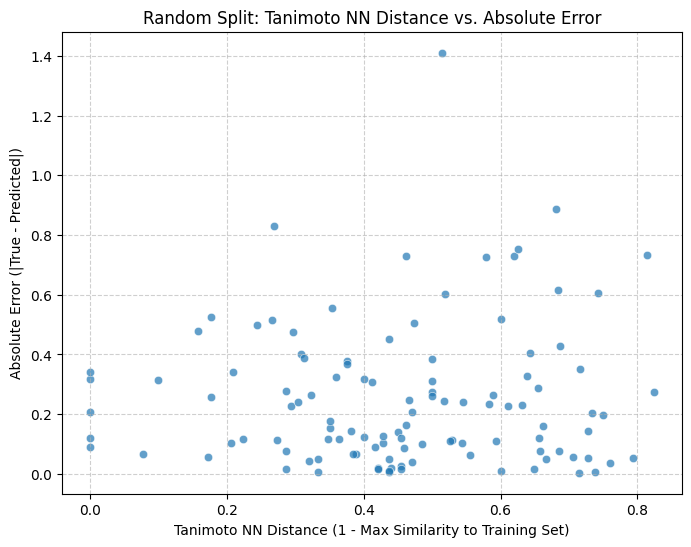

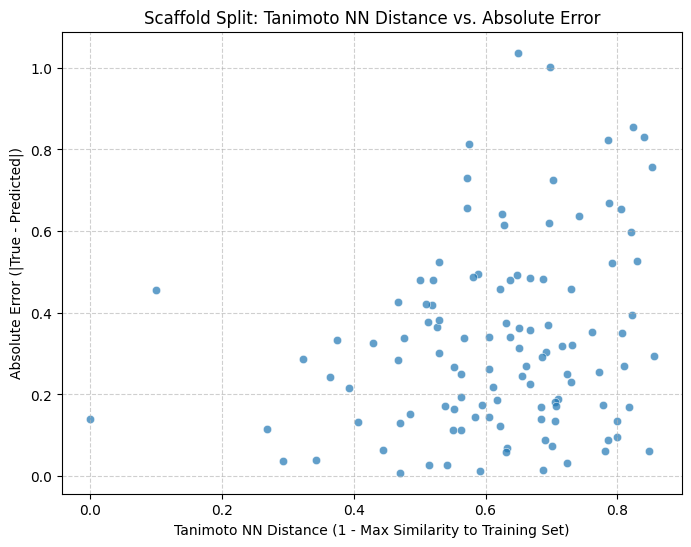

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Random Split Scatter Plot ---
plt.figure(figsize=(8, 6))
sns.scatterplot(x='tanimoto_nn_distance', y='error', data=random_error_df, alpha=0.7)
plt.title('Random Split: Tanimoto NN Distance vs. Absolute Error')
plt.xlabel('Tanimoto NN Distance (1 - Max Similarity to Training Set)')
plt.ylabel('Absolute Error (|True - Predicted|)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# --- Scaffold Split Scatter Plot ---
plt.figure(figsize=(8, 6))
sns.scatterplot(x='tanimoto_nn_distance', y='error', data=scaffold_error_df, alpha=0.7)
plt.title('Scaffold Split: Tanimoto NN Distance vs. Absolute Error')
plt.xlabel('Tanimoto NN Distance (1 - Max Similarity to Training Set)')
plt.ylabel('Absolute Error (|True - Predicted|)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Regression Analysis: Tanimoto Nearest Neighbor Distance vs. Absolute Error

To further quantify the relationship observed (or not observed) in the scatter plots and correlation coefficients, we'll perform a simple linear regression. This will allow us to model 'error' as a function of 'tanimoto_nn_distance' and understand the strength and direction of this linear dependency.

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# --- Regression for Random Split ---
X_random = random_error_df[['tanimoto_nn_distance']]
y_random = random_error_df['error']

model_random = LinearRegression()
model_random.fit(X_random, y_random)

# Make predictions for R-squared calculation
y_pred_random = model_random.predict(X_random)
r2_random = r2_score(y_random, y_pred_random)

print("--- Random Split Regression Analysis ---")
print(f"Intercept: {model_random.intercept_:.4f}")
print(f"Coefficient (Tanimoto NN Distance): {model_random.coef_[0]:.4f}")
print(f"R-squared: {r2_random:.4f}")

# --- Regression for Scaffold Split ---
X_scaffold = scaffold_error_df[['tanimoto_nn_distance']]
y_scaffold = scaffold_error_df['error']

model_scaffold = LinearRegression()
model_scaffold.fit(X_scaffold, y_scaffold)

# Make predictions for R-squared calculation
y_pred_scaffold = model_scaffold.predict(X_scaffold)
r2_scaffold = r2_score(y_scaffold, y_pred_scaffold)

print("\n--- Scaffold Split Regression Analysis ---")
print(f"Intercept: {model_scaffold.intercept_:.4f}")
print(f"Coefficient (Tanimoto NN Distance): {model_scaffold.coef_[0]:.4f}")
print(f"R-squared: {r2_scaffold:.4f}")

--- Random Split Regression Analysis ---
Intercept: 0.2215
Coefficient (Tanimoto NN Distance): 0.0642
R-squared: 0.0028

--- Scaffold Split Regression Analysis ---
Intercept: 0.1121
Coefficient (Tanimoto NN Distance): 0.3459
R-squared: 0.0536


### Sanity Check: Descriptive Statistics for Structural Features

We will now use the `describe()` method on the structural feature columns to get a statistical summary (count, mean, std, min, max, quartiles). This helps in quickly understanding the distribution and range of these new features.

In [19]:
structural_feature_columns = [
    'ring_count',
    'aromatic_rings',
    'heteroatom_count',
    'rotatable_bonds',
    'mol_weight',
    'logp',
    'tpsa',
    'hbd',
    'hba'
]

print("\n--- Random Split Structural Features Description ---")
display(random_error_df[structural_feature_columns].describe())

print("\n--- Scaffold Split Structural Features Description ---")
display(scaffold_error_df[structural_feature_columns].describe())


--- Random Split Structural Features Description ---


,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba
count,113.000000,113.000000,113.000000,113.000000,113.00000,113.000000,113.000000,113.000000,113.000000
mean,1.247788,0.964602,3.115044,2.106195,185.09492,2.104844,35.337257,0.787611,2.017699
std,1.022348,0.865295,2.617770,2.376833,88.71496,1.820474,36.196145,1.206022,1.986482
min,0.000000,0.000000,0.000000,0.000000,30.07000,-5.395600,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,0.000000,112.21600,1.185000,0.000000,0.000000,1.000000
50%,1.000000,1.000000,2.000000,1.000000,168.10800,1.889200,26.030000,0.000000,1.000000
75%,2.000000,2.000000,5.000000,3.000000,248.30700,2.934500,55.120000,1.000000,3.000000
max,4.000000,3.000000,11.000000,13.000000,402.48700,7.274000,189.530000,8.000000,11.000000



--- Scaffold Split Structural Features Description ---


,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba
count,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000
mean,2.769912,1.663717,4.752212,2.061947,270.737398,2.546486,54.236195,1.176991,3.238938
std,1.210142,1.243631,3.326117,2.304046,100.781186,2.482617,46.883027,1.717713,2.784762
min,1.000000,0.000000,0.000000,0.000000,58.080000,-7.571400,0.000000,0.000000,0.000000
25%,2.000000,1.000000,3.000000,0.000000,212.252000,1.171600,25.780000,0.000000,1.000000
50%,3.000000,2.000000,4.000000,2.000000,261.064000,2.669100,43.370000,1.000000,3.000000
75%,3.000000,2.000000,7.000000,3.000000,337.463000,4.198300,73.800000,2.000000,4.000000
max,7.000000,5.000000,16.000000,9.000000,588.562000,7.725600,268.680000,11.000000,16.000000


### Checking for NaN Values in DataFrames

It's good practice to check for any missing (NaN) values in your DataFrames, especially after performing operations that involve data transformations or merging. We can use the `.isnull().sum()` method on our DataFrames to get a count of NaN values for each column.

In [20]:
print("\n--- NaN values in Random Split DataFrame ---")
display(random_error_df.isnull().sum())

print("\n--- NaN values in Scaffold Split DataFrame ---")
display(scaffold_error_df.isnull().sum())


--- NaN values in Random Split DataFrame ---


,0
smiles,0
true_value,0
predicted_value,0
error,0
ring_count,0
aromatic_rings,0
heteroatom_count,0
rotatable_bonds,0
mol_weight,0
logp,0



--- NaN values in Scaffold Split DataFrame ---


,0
smiles,0
true_value,0
predicted_value,0
error,0
ring_count,0
aromatic_rings,0
heteroatom_count,0
rotatable_bonds,0
mol_weight,0
logp,0


The output above shows the number of NaN values in each column. If all counts are 0, it means there are no missing values in that column. If there are non-zero values, it indicates the presence of missing data.

In [21]:
print("\n--- Info for Random Split DataFrame ---")
random_error_df.info()

print("\n--- Info for Scaffold Split DataFrame ---")
scaffold_error_df.info()


--- Info for Random Split DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   smiles                113 non-null    object 
 1   true_value            113 non-null    float32
 2   predicted_value       113 non-null    float32
 3   error                 113 non-null    float32
 4   ring_count            113 non-null    int64  
 5   aromatic_rings        113 non-null    int64  
 6   heteroatom_count      113 non-null    int64  
 7   rotatable_bonds       113 non-null    int64  
 8   mol_weight            113 non-null    float64
 9   logp                  113 non-null    float64
 10  tpsa                  113 non-null    float64
 11  hbd                   113 non-null    int64  
 12  hba                   113 non-null    int64  
 13  tanimoto_nn_distance  113 non-null    float64
dtypes: float32(3), float64(4), int64(

### Summary Statistics for Absolute Error

We'll now examine the descriptive statistics for the `error` column in both the random and scaffold split DataFrames. This provides a quick numerical summary of the error distribution, including mean, standard deviation, and quartiles.

In [25]:
print("\n--- Random Split Error Statistics ---")
display(random_error_df['error'].describe())

print("\n--- Scaffold Split Error Statistics ---")
display(scaffold_error_df['error'].describe())


--- Random Split Error Statistics ---


,error
count,113.000000
mean,0.250676
std,0.236342
min,0.003627
25%,0.075853
50%,0.198566
75%,0.340791
max,1.410667



--- Scaffold Split Error Statistics ---


,error
count,113.000000
mean,0.326458
std,0.227933
min,0.008175
25%,0.144745
50%,0.292348
75%,0.458303
max,1.036807


### Comparing 'mol_weight' distribution for high vs. low error molecules

To understand if molecular weight influences prediction error, we'll divide the molecules into 'high error' and 'low error' groups based on the median absolute error for each split. Then, we'll examine the descriptive statistics and visualize the distributions of 'mol_weight' for these groups.

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate median error for each split
median_error_random = random_error_df['error'].median()
median_error_scaffold = scaffold_error_df['error'].median()

# Create high and low error groups for random split
random_high_error_df = random_error_df[random_error_df['error'] >= median_error_random]
random_low_error_df = random_error_df[random_error_df['error'] < median_error_random]

# Create high and low error groups for scaffold split
scaffold_high_error_df = scaffold_error_df[scaffold_error_df['error'] >= median_error_scaffold]
scaffold_low_error_df = scaffold_error_df[scaffold_error_df['error'] < median_error_scaffold]

print("--- Random Split - Mol_Weight Description for Low Error Molecules ---")
display(random_low_error_df['mol_weight'].describe())

print("\n--- Random Split - Mol_Weight Description for High Error Molecules ---")
display(random_high_error_df['mol_weight'].describe())

print("\n--- Scaffold Split - Mol_Weight Description for Low Error Molecules ---")
display(scaffold_low_error_df['mol_weight'].describe())

print("\n--- Scaffold Split - Mol_Weight Description for High Error Molecules ---")
display(scaffold_high_error_df['mol_weight'].describe())

--- Random Split - Mol_Weight Description for Low Error Molecules ---


,mol_weight
count,56.000000
mean,190.221821
std,91.637950
min,56.064000
25%,118.167250
50%,176.259000
75%,255.829500
max,402.487000



--- Random Split - Mol_Weight Description for High Error Molecules ---


,mol_weight
count,57.000000
mean,180.057965
std,86.261353
min,30.070000
25%,110.181000
50%,145.161000
75%,226.448000
max,366.000000



--- Scaffold Split - Mol_Weight Description for Low Error Molecules ---


,mol_weight
count,56.000000
mean,252.959696
std,83.940014
min,84.143000
25%,207.503750
50%,252.793000
75%,293.364500
max,502.920000



--- Scaffold Split - Mol_Weight Description for High Error Molecules ---


,mol_weight
count,57.000000
mean,288.203211
std,112.991329
min,58.080000
25%,230.310000
50%,270.372000
75%,364.914000
max,588.562000


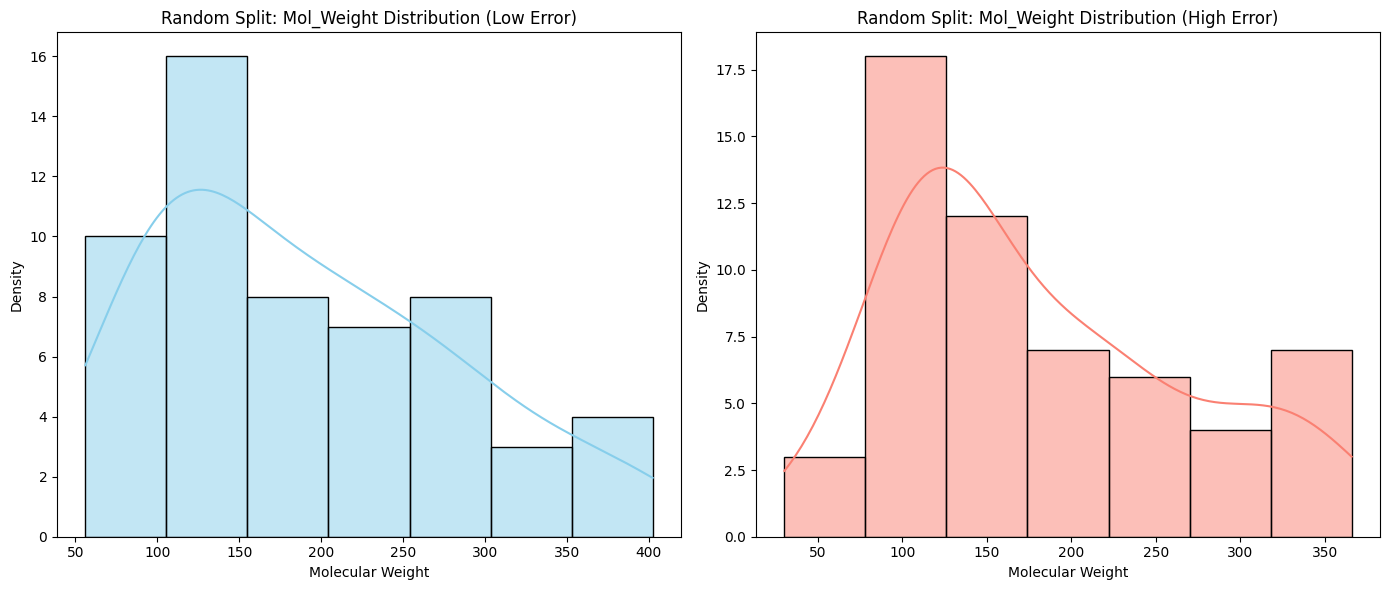

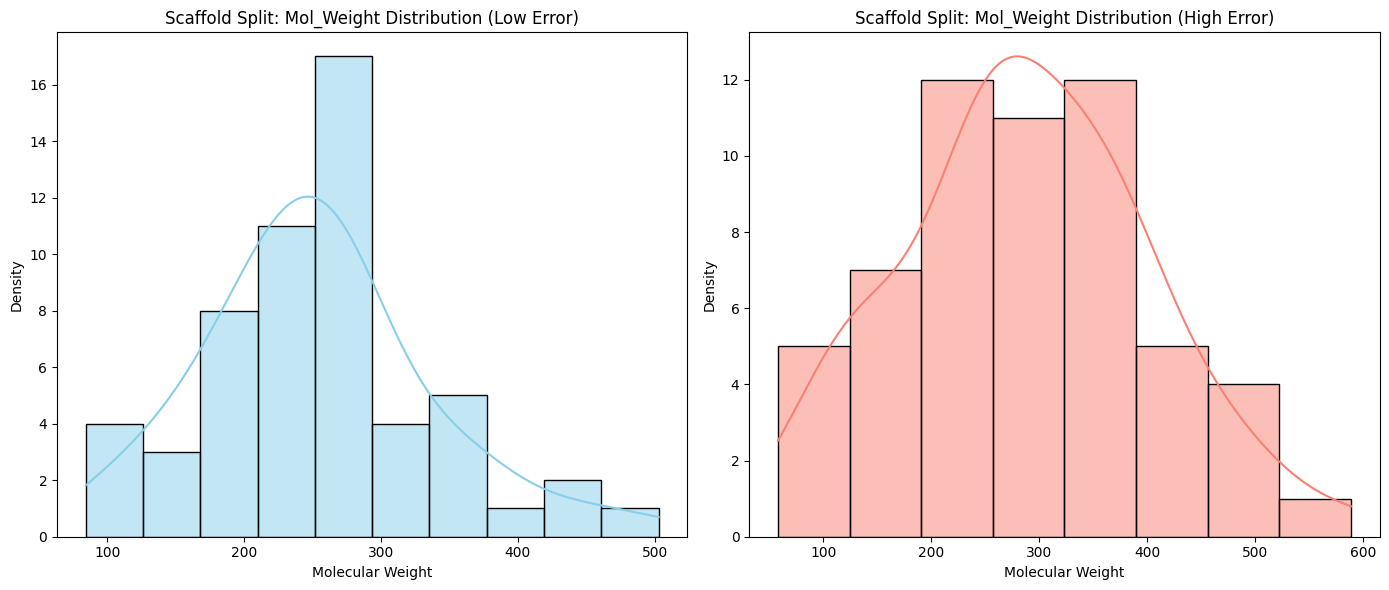

In [27]:
# Visualize mol_weight distributions for Random Split
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(random_low_error_df['mol_weight'], kde=True, color='skyblue')
plt.title('Random Split: Mol_Weight Distribution (Low Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.subplot(1, 2, 2)
sns.histplot(random_high_error_df['mol_weight'], kde=True, color='salmon')
plt.title('Random Split: Mol_Weight Distribution (High Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

# Visualize mol_weight distributions for Scaffold Split
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(scaffold_low_error_df['mol_weight'], kde=True, color='skyblue')
plt.title('Scaffold Split: Mol_Weight Distribution (Low Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.subplot(1, 2, 2)
sns.histplot(scaffold_high_error_df['mol_weight'], kde=True, color='salmon')
plt.title('Scaffold Split: Mol_Weight Distribution (High Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

### Statistical Analysis: Mann-Whitney U Test for Scaffold Split Features

We will now use the `scipy.stats` library to determine if the differences in structural features between the high and low error molecules in the scaffold split are statistically significant.

In [30]:
from scipy.stats import mannwhitneyu

features_to_analyze = ['logp', 'mol_weight', 'tpsa', 'ring_count', 'tanimoto_nn_distance']
results = []

for feat in features_to_analyze:
    stat, p_value = mannwhitneyu(
        scaffold_high_error_df[feat],
        scaffold_low_error_df[feat],
        alternative='two-sided'
    )
    results.append({
        'Feature': feat,
        'High Error Mean': scaffold_high_error_df[feat].mean(),
        'Low Error Mean': scaffold_low_error_df[feat].mean(),
        'U-Statistic': stat,
        'P-Value': p_value
    })

# Create a summary DataFrame for the results
stats_df = pd.DataFrame(results)
print("--- Mann-Whitney U Test Results (Scaffold Split) ---")
display(stats_df)

# Highlight significant features (p < 0.05)
significant = stats_df[stats_df['P-Value'] < 0.05]
print(f"\nFeatures with significant differences in distribution: {significant['Feature'].tolist()}")

--- Mann-Whitney U Test Results (Scaffold Split) ---


,Feature,High Error Mean,Low Error Mean,U-Statistic,P-Value
0,logp,2.698062,2.392203,1766.5,0.328945
1,mol_weight,288.203211,252.959696,1937.5,0.050199
2,tpsa,56.147018,52.291250,1552.0,0.802399
3,ring_count,2.894737,2.642857,1737.0,0.399741
4,tanimoto_nn_distance,0.642888,0.596118,1846.5,0.151084



Features with significant differences in distribution: []


### Multivariate Analysis: Controlling for Novelty

To answer if these features predict error *after* controlling for Tanimoto distance, we will run a Multiple Linear Regression on the scaffold split data.

In [31]:
import statsmodels.api as sm

# Define the predictors (Structural Features + Tanimoto Distance)
X = scaffold_error_df[['tanimoto_nn_distance', 'logp', 'mol_weight', 'tpsa', 'ring_count']]
y = scaffold_error_df['error']

# Add a constant for the intercept
X = sm.add_constant(X)

# Fit the OLS model
ols_model = sm.OLS(y, X).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.151
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                     3.809
Date:                Sun, 14 Jun 2026   Prob (F-statistic):            0.00325
Time:                        15:35:53   Log-Likelihood:                 16.510
No. Observations:                 113   AIC:                            -21.02
Df Residuals:                     107   BIC:                            -4.656
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.0747 

### Interaction Analysis: Does Novelty Amplify Structural Predictors?

We will now create interaction terms between our structural features and `tanimoto_nn_distance`. This helps determine if the model's struggle with certain properties (like high Ring Count or MW) is significantly worsened when the molecule belongs to a novel scaffold.

In [32]:
# Create interaction terms
scaffold_error_df['mw_x_novelty'] = scaffold_error_df['mol_weight'] * scaffold_error_df['tanimoto_nn_distance']
scaffold_error_df['rings_x_novelty'] = scaffold_error_df['ring_count'] * scaffold_error_df['tanimoto_nn_distance']

# Define predictors including interaction terms
X_interact = scaffold_error_df[['tanimoto_nn_distance', 'logp', 'mol_weight', 'tpsa', 'ring_count', 'mw_x_novelty', 'rings_x_novelty']]
X_interact = sm.add_constant(X_interact)

# Fit the OLS model with interactions
interaction_model = sm.OLS(scaffold_error_df['error'], X_interact).fit()

print("--- OLS Regression with Interaction Terms ---")
print(interaction_model.summary())

--- OLS Regression with Interaction Terms ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.178
Model:                            OLS   Adj. R-squared:                  0.123
Method:                 Least Squares   F-statistic:                     3.240
Date:                Sun, 14 Jun 2026   Prob (F-statistic):            0.00375
Time:                        15:39:30   Log-Likelihood:                 18.305
No. Observations:                 113   AIC:                            -20.61
Df Residuals:                     105   BIC:                             1.209
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

### Refined Multivariate Analysis: Incorporating Specific Structural Descriptors

We are expanding our feature set to include `aromatic_rings`, `rotatable_bonds`, and `heteroatom_count`. This allows us to see if specific architectural properties of the molecules are driving prediction errors in the scaffold split.

In [33]:
import statsmodels.api as sm

# Define the expanded set of predictors
# Note: We keep tanimoto_nn_distance to continue controlling for structural novelty
refined_features = [
    'tanimoto_nn_distance',
    'aromatic_rings',
    'rotatable_bonds',
    'heteroatom_count',
    'logp',
    'mol_weight'
]

X_refined = scaffold_error_df[refined_features]
X_refined = sm.add_constant(X_refined)
y = scaffold_error_df['error']

# Fit the refined OLS model
refined_model = sm.OLS(y, X_refined).fit()

print("--- Refined OLS Regression Results (Scaffold Split) ---")
print(refined_model.summary())

--- Refined OLS Regression Results (Scaffold Split) ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.149
Model:                            OLS   Adj. R-squared:                  0.100
Method:                 Least Squares   F-statistic:                     3.085
Date:                Sun, 14 Jun 2026   Prob (F-statistic):            0.00800
Time:                        15:47:47   Log-Likelihood:                 16.349
No. Observations:                 113   AIC:                            -18.70
Df Residuals:                     106   BIC:                            0.3945
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

### Visualizing the Residuals of the Refined Model

To identify if the model consistently fails on specific types of molecules, we will plot the residuals against the most significant structural features.

/tmp/ipykernel_3869/3970491114.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='aromatic_rings', y='residuals', data=scaffold_error_df, palette='Set2')


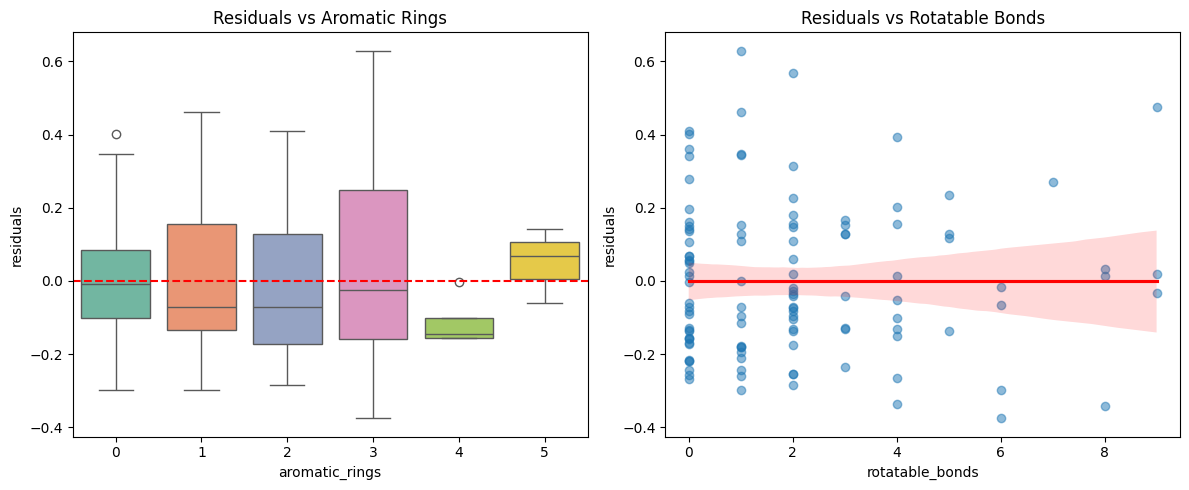

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Add residuals to the dataframe for plotting
scaffold_error_df['residuals'] = refined_model.resid

plt.figure(figsize=(12, 5))

# Plot Residuals vs Aromatic Rings
plt.subplot(1, 2, 1)
sns.boxplot(x='aromatic_rings', y='residuals', data=scaffold_error_df, palette='Set2')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Aromatic Rings')

# Plot Residuals vs Rotatable Bonds
plt.subplot(1, 2, 2)
sns.regplot(x='rotatable_bonds', y='residuals', data=scaffold_error_df, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title('Residuals vs Rotatable Bonds')

plt.tight_layout()
plt.show()

### Directional Bias Analysis: Is the Model Systematically Over- or Under-Predicting?

We will analyze the sign of the residuals (True - Predicted) to see if the model has a systematic bias for high-error molecules in the scaffold split.

--- Residual Bias Summary (True - Predicted) ---


/tmp/ipykernel_3869/2851909401.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bias_summary = scaffold_error_df.groupby('error_group')['bias'].agg(['mean', 'std', 'count'])


,mean,std,count
error_group,,,
Low Error,0.036133,0.168768,57
High Error,0.107754,0.531586,56


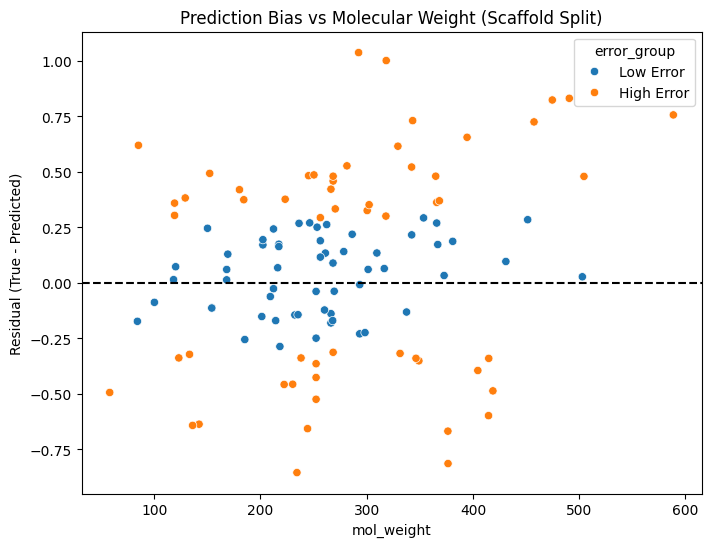

In [35]:
scaffold_error_df['bias'] = scaffold_error_df['true_value'] - scaffold_error_df['predicted_value']

# Grouping by error severity
scaffold_error_df['error_group'] = pd.qcut(scaffold_error_df['error'], 2, labels=['Low Error', 'High Error'])

bias_summary = scaffold_error_df.groupby('error_group')['bias'].agg(['mean', 'std', 'count'])
print("--- Residual Bias Summary (True - Predicted) ---")
display(bias_summary)

# Visualization of bias vs Molecular Weight
plt.figure(figsize=(8, 6))
sns.scatterplot(x='mol_weight', y='bias', hue='error_group', data=scaffold_error_df)
plt.axhline(0, color='black', linestyle='--')
plt.title('Prediction Bias vs Molecular Weight (Scaffold Split)')
plt.ylabel('Residual (True - Predicted)')
plt.show()